In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

X_train = pd.read_csv("../data/processed/X_train_clip.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
print(X_train.shape)

(8402, 63)


Most negative (higher value = less bankruptcy):
Attr39   -0.132
Attr42   -0.127
Attr13   -0.126
Attr38   -0.125
Attr19   -0.118
Attr23   -0.117
Attr10   -0.116
Attr35   -0.115
dtype: float64

Most positive (higher value = more bankruptcy):
Attr20    0.038
Attr52    0.061
Attr32    0.073
Attr30    0.073
Attr58    0.076
Attr62    0.095
Attr2     0.113
Attr51    0.115
dtype: float64


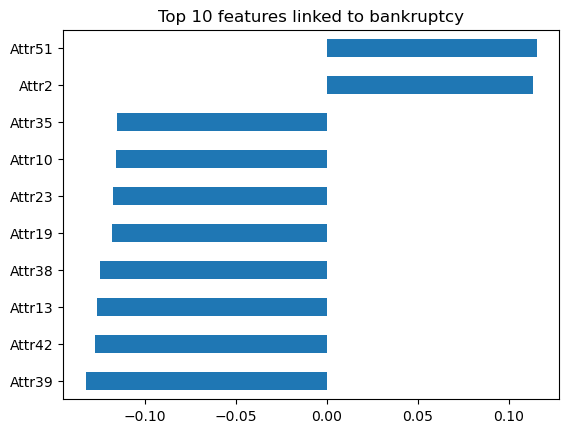

In [3]:
# 1. Correlation with bankruptcy
corr = X_train.corrwith(y_train)

print("Most negative (higher value = less bankruptcy):")
print(corr.sort_values().head(8).round(3))
print()
print("Most positive (higher value = more bankruptcy):")
print(corr.sort_values().tail(8).round(3))

top10 = corr.abs().sort_values(ascending=False).head(10).index
corr[top10].sort_values().plot(kind="barh")
plt.title("Top 10 features linked to bankruptcy")
plt.show()

In [4]:
# 2. t-test for every feature
results = []
for col in X_train.columns:
    healthy = X_train.loc[y_train == 0, col]
    bankrupt = X_train.loc[y_train == 1, col]
    t, p = stats.ttest_ind(bankrupt, healthy, equal_var=False)
    results.append((col, t, p))

ttest_df = pd.DataFrame(results, columns=["feature", "t_stat", "p_value"])
ttest_df = ttest_df.sort_values("p_value")

print(ttest_df.head(10))
print("Features with p < 0.001:", (ttest_df["p_value"] < 0.001).sum(), "of", len(ttest_df))

   feature     t_stat       p_value
25  Attr26 -11.023596  1.793816e-25
15  Attr16 -11.014420  1.932553e-25
23  Attr24 -10.774004  3.496418e-24
12  Attr13 -10.454091  6.340634e-23
34  Attr35  -9.616411  6.028344e-20
36  Attr38  -9.534930  1.215621e-19
11  Attr12  -9.296389  5.346993e-19
37  Attr39  -9.205523  1.676387e-18
0    Attr1  -9.188581  1.750071e-18
17  Attr18  -9.081998  3.958421e-18
Features with p < 0.001: 42 of 63


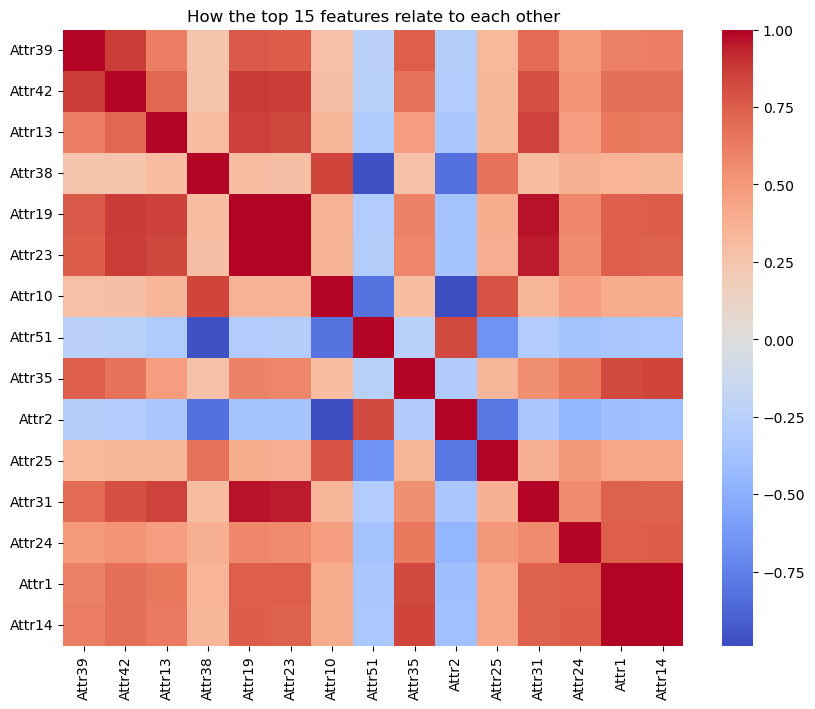

In [5]:
# 3. Heatmap: which top features look alike?
top15 = corr.abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(X_train[top15].corr(), cmap="coolwarm", center=0)
plt.title("How the top 15 features relate to each other")
plt.show()

In [6]:
# 4. Which pairs are almost copies?
corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)

print(pairs.head(10).round(3))
print("Pairs with correlation above 0.9:", (pairs > 0.9).sum())

Attr7   Attr14    1.000
Attr14  Attr18    0.999
Attr7   Attr18    0.999
Attr8   Attr17    0.998
Attr16  Attr26    0.995
Attr28  Attr54    0.993
Attr1   Attr7     0.991
        Attr14    0.991
        Attr18    0.990
Attr2   Attr10    0.989
dtype: float64
Pairs with correlation above 0.9: 29
